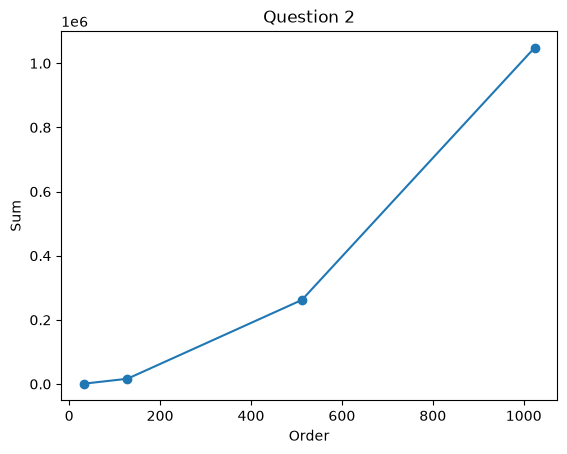

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def augmented_matrix(matrixA,vectorB):
    rows,cols = matrixA.shape
    vectorB_new = vectorB.reshape(-1,1)   #To change the vector from row matrix to column matrix
    aug = np.concatenate((matrixA,vectorB_new), axis = 1)
    #print(aug)
    return aug

def forward_elimination(aug):
    rows,cols = aug.shape
    for i in range(1,rows,1):
        for j in range(0,i,1):
            prefac = (aug[i][j] / aug[j][j])
            aug[i]=aug[i] - (prefac*aug[j])
    #print(aug)
    return aug

def backward_substitution(aug):
    rows,cols = aug.shape
    x = np.zeros(rows)
    for i in range(rows-1,-1,-1):
        sum = 0
        for j in range(0,rows,1):
            sum = sum + (x[j] * aug[i][j])
        x[i] = (aug[i][rows] - sum)/(aug[i][i])
    #print(x)
    return x

n = [ 32, 128, 512, 1024]
sum_list = []
for i in n:
    vectorB = np.ones((1,i), dtype=float)
    matrixA = np.zeros((i,i), dtype = float)
    for j in range(0,i,1):
        for k in range(0,i,1):
            matrixA[j][k] = max(j+1,k+1)
    aug = augmented_matrix(matrixA,vectorB)
    aug1 = forward_elimination(aug)
    aug2 = backward_substitution(aug1)
    sum = 0.0
    for t in range(0,i,1):
        sum = sum + ((aug2[t])**2)
    ratio = 1/sum
    sum_list.append(ratio)
arr_order = np.array(n)
arr_sum = np.array(sum_list)
plt.plot(arr_order,arr_sum, marker='o')
plt.xlabel('Order')
plt.ylabel('Sum')
plt.title('Question 2')
plt.show()
        